# 11 — Time-Series Sensor Forecasting

## Smart Manufacturing Digital Twin

### Purpose

This notebook adds the **Time Series** requirement to the existing Smart Manufacturing Digital Twin project.

The existing system already predicts:

- failure probability
- Remaining Useful Life (RUL)
- machine status
- maintenance decisions
- alerts
- LLM-based maintenance intelligence

This notebook adds a separate capability:

> **Predict future sensor values from historical machine telemetry.**

The forecasted sensor values can later be compared with actual incoming values. A large difference between expected and actual behavior can become an additional degradation/anomaly signal for the Smart Twin.

### Pipeline

```text
Historical IoT telemetry
        ↓
Sort by Machine_ID + Cycle
        ↓
Create lag features
        ↓
Chronological train/test split
        ↓
Train forecasting models
        ↓
Evaluate MAE / RMSE
        ↓
Actual vs predicted plots
        ↓
Recursive future forecasting
        ↓
time_series_forecasts.csv
        ↓
Future integration with Smart Twin / monitoring
```

### Important design choice

This is **not a random train/test split**. Time-series data must respect chronological order so that future information does not leak into the past.


## STEP 1 — Imports and configuration

We use a lag-feature approach with `RandomForestRegressor`.

For each sensor, the model learns relationships such as:

```text
sensor(t-1), sensor(t-2), sensor(t-3), ...
                    ↓
               sensor(t)
```

This keeps the implementation lightweight and reproducible for the capstone while still demonstrating a proper forecasting workflow.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42

# Notebook is inside notebooks/, so project data is one level above.
DATA_PATH = "../data/iot/iot_simulation_data.csv"
FORECAST_OUTPUT_PATH = "../data/processed/time_series_forecasts.csv"
METRICS_OUTPUT_PATH = "../data/processed/time_series_forecast_metrics.csv"

print("Configuration loaded.")
print("Data path:", DATA_PATH)


Configuration loaded.
Data path: ../data/iot/iot_simulation_data.csv


## STEP 2 — Load the IoT simulation data

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())


Shape: (1930, 16)


,Timestamp,Machine_ID,Machine_Type,Cycle,Temperature_C,Vibration_mm_s,Pressure_bar,Rotational_Speed_RPM,Load_Fraction,Torque_Nm,Current_A,Acoustic_dB,Wear_Level,Health_Index,Anomaly_Score,Simulation_Fault
0,2026-08-01 08:00:00,CNC_001,CNC_Mill,1,69.030303,0.213912,2.113994,1517.415010,0.656548,46.756227,9.199260,55.818277,0.0000,100.000,0.1342,BEARING_WEAR
1,2026-08-01 08:01:00,CNC_001,CNC_Mill,2,69.089661,0.167449,2.139051,1517.500142,0.594057,46.788014,9.444278,55.515707,0.0000,99.961,0.2990,BEARING_WEAR
2,2026-08-01 08:02:00,CNC_001,CNC_Mill,3,69.030239,0.246411,2.120718,1522.832970,0.628487,46.321709,9.651838,54.939203,0.0022,99.760,0.2269,BEARING_WEAR
3,2026-08-01 08:03:00,CNC_001,CNC_Mill,4,69.040893,0.205632,2.114275,1534.355835,0.695731,48.495093,9.884200,54.581711,0.0000,99.884,0.0469,BEARING_WEAR
4,2026-08-01 08:04:00,CNC_001,CNC_Mill,5,68.651431,0.200355,2.085129,1515.119912,0.593584,48.107525,9.029107,54.332662,0.0006,99.802,0.2841,BEARING_WEAR



Columns:
['Timestamp', 'Machine_ID', 'Machine_Type', 'Cycle', 'Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM', 'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB', 'Wear_Level', 'Health_Index', 'Anomaly_Score', 'Simulation_Fault']


## STEP 3 — Validate the time-series structure

For this project, `Cycle` is the operating-time axis for each machine.

We therefore sort independently by:

1. `Machine_ID`
2. `Cycle`

This prevents observations from different machines from being mixed together.


In [3]:
required_columns = [
    "Machine_ID",
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar"
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[required_columns + [c for c in df.columns if c not in required_columns]].copy()

df["Machine_ID"] = df["Machine_ID"].astype(str)
df["Cycle"] = pd.to_numeric(df["Cycle"], errors="coerce")

df = df.dropna(subset=["Machine_ID", "Cycle"])
df = df.sort_values(["Machine_ID", "Cycle"]).reset_index(drop=True)

print("Machines:", df["Machine_ID"].nunique())
print("Cycle range:", df["Cycle"].min(), "to", df["Cycle"].max())

display(
    df.groupby("Machine_ID")["Cycle"]
      .agg(["min", "max", "count"])
      .reset_index()
      .head(20)
)


Machines: 7
Cycle range: 1 to 330


,Machine_ID,min,max,count
0,CNC_001,1,260,260
1,COMP_003,1,290,290
2,MOTOR_004,1,240,240
3,PRESS_006,1,275,275
4,PUMP_002,1,310,310
5,ROBOT_007,1,225,225
6,TURB_005,1,330,330


## STEP 4 — Select sensors for forecasting

We forecast three important sensor signals:

- **Temperature**
- **Vibration**
- **Pressure**

These are useful for demonstrating thermal, mechanical, and process-condition forecasting.

The architecture can later be extended to:

- rotational speed
- torque
- current
- acoustic level
- load fraction


In [4]:
SENSORS = [
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar"
]

print("Sensors selected for forecasting:")
for sensor in SENSORS:
    print("-", sensor)


Sensors selected for forecasting:
- Temperature_C
- Vibration_mm_s
- Pressure_bar


## STEP 5 — Explore sensor behavior

Before training, inspect representative machine trajectories.

The plots below show how sensor values change over operating cycles.


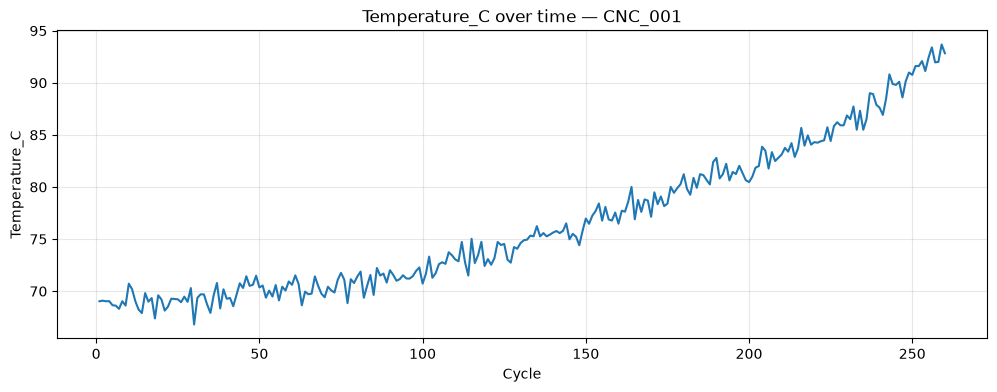

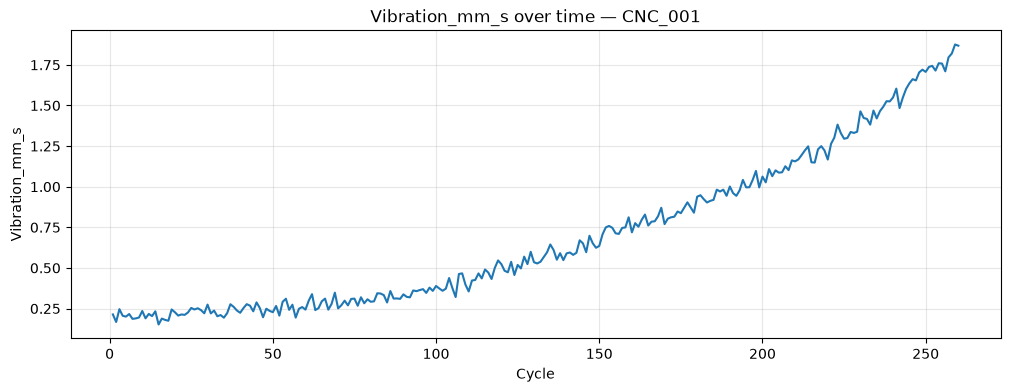

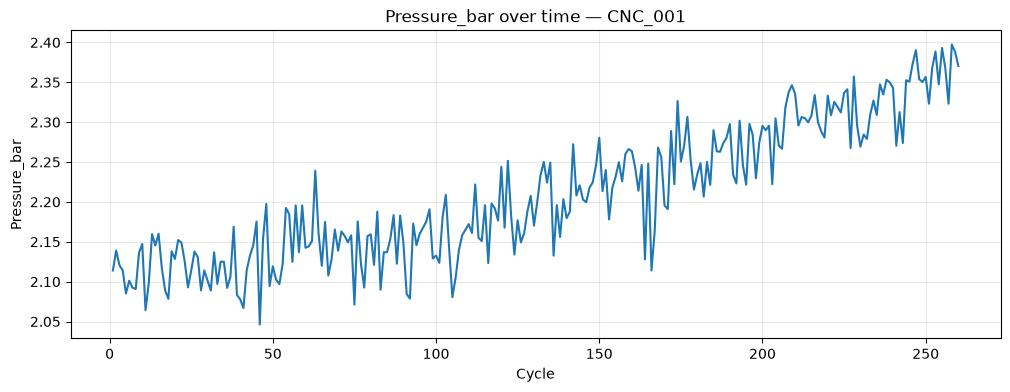

In [5]:
sample_machine = df["Machine_ID"].iloc[0]

sample = df[df["Machine_ID"] == sample_machine].sort_values("Cycle")

for sensor in SENSORS:
    plt.figure(figsize=(12, 4))
    plt.plot(sample["Cycle"], sample[sensor])
    plt.title(f"{sensor} over time — {sample_machine}")
    plt.xlabel("Cycle")
    plt.ylabel(sensor)
    plt.grid(True, alpha=0.3)
    plt.show()


## STEP 6 — Create lag features

Lag features convert a time series into a supervised-learning problem.

For example, with three lags:

```text
sensor(t-3)
sensor(t-2)
sensor(t-1)
      ↓
sensor(t)
```

We use lags:

```text
1, 2, 3, 5, 10
```

The features are created separately for each machine so one machine's history never becomes another machine's history.


In [6]:
LAGS = [1, 2, 3, 5, 10]

def create_lag_features(data, sensor, lags=LAGS):
    result = data[["Machine_ID", "Cycle", sensor]].copy()

    for lag in lags:
        result[f"{sensor}_lag_{lag}"] = (
            result.groupby("Machine_ID")[sensor].shift(lag)
        )

    result = result.dropna().reset_index(drop=True)
    return result

lag_preview = create_lag_features(df, SENSORS[0])

display(lag_preview.head(10))
print("Lagged dataset shape:", lag_preview.shape)


,Machine_ID,Cycle,Temperature_C,Temperature_C_lag_1,Temperature_C_lag_2,Temperature_C_lag_3,Temperature_C_lag_5,Temperature_C_lag_10
0,CNC_001,11,70.186647,70.719612,68.620336,69.033821,68.610849,69.030303
1,CNC_001,12,69.034457,70.186647,70.719612,68.620336,68.304690,69.089661
2,CNC_001,13,68.231614,69.034457,70.186647,70.719612,69.033821,69.030239
3,CNC_001,14,67.898965,68.231614,69.034457,70.186647,68.620336,69.040893
4,CNC_001,15,69.815477,67.898965,68.231614,69.034457,70.719612,68.651431
5,CNC_001,16,68.992325,69.815477,67.898965,68.231614,70.186647,68.610849
6,CNC_001,17,69.337687,68.992325,69.815477,67.898965,69.034457,68.304690
7,CNC_001,18,67.387513,69.337687,68.992325,69.815477,68.231614,69.033821
8,CNC_001,19,69.603603,67.387513,69.337687,68.992325,67.898965,68.620336
9,CNC_001,20,69.202090,69.603603,67.387513,69.337687,69.815477,70.719612


Lagged dataset shape: (1860, 8)


## STEP 7 — Chronological train/test split

A time-series model must not randomly shuffle future observations into the training set.

For each machine:

- first 80% of chronological observations → training
- last 20% → testing

This better represents the real deployment situation:

> train on the past → predict the future.


In [7]:
def chronological_split(data, train_fraction=0.80):
    data = data.sort_values(["Machine_ID", "Cycle"]).reset_index(drop=True)

    train_parts = []
    test_parts = []

    for machine_id, group in data.groupby("Machine_ID", sort=False):
        group = group.sort_values("Cycle").reset_index(drop=True)

        split_idx = int(len(group) * train_fraction)
        split_idx = max(split_idx, 1)

        train_parts.append(group.iloc[:split_idx])
        test_parts.append(group.iloc[split_idx:])

    train = pd.concat(train_parts, ignore_index=True)
    test = pd.concat(test_parts, ignore_index=True)

    return train, test

print("Function ready.")


Function ready.


## STEP 8 — Train one forecasting model per machine and sensor

The model predicts each sensor independently.

Why?

Different machines can have different normal operating ranges and degradation patterns. A per-machine model keeps the demonstration straightforward and avoids mixing unrelated machine histories.

The model is a `RandomForestRegressor` trained only on chronological historical data.


In [8]:
model_results = []
trained_models = {}

for machine_id in sorted(df["Machine_ID"].unique()):
    machine_df = df[df["Machine_ID"] == machine_id].sort_values("Cycle").copy()

    for sensor in SENSORS:
        series = create_lag_features(machine_df, sensor)

        if len(series) < 30:
            print(f"Skipping {machine_id} / {sensor}: insufficient history ({len(series)} rows)")
            continue

        train, test = chronological_split(series, train_fraction=0.80)

        feature_cols = [f"{sensor}_lag_{lag}" for lag in LAGS]

        X_train = train[feature_cols]
        y_train = train[sensor]
        X_test = test[feature_cols]
        y_test = test[sensor]

        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))

        key = (machine_id, sensor)
        trained_models[key] = {
            "model": model,
            "feature_cols": feature_cols,
            "train": train,
            "test": test
        }

        model_results.append({
            "Machine_ID": machine_id,
            "Sensor": sensor,
            "Train_Rows": len(train),
            "Test_Rows": len(test),
            "MAE": mae,
            "RMSE": rmse
        })

metrics_df = pd.DataFrame(model_results)

print("Models trained:", len(metrics_df))
display(metrics_df)


Models trained: 21


,Machine_ID,Sensor,Train_Rows,Test_Rows,MAE,RMSE
0,CNC_001,Temperature_C,200,50,5.097954,5.970408
1,CNC_001,Vibration_mm_s,200,50,0.347378,0.407473
2,CNC_001,Pressure_bar,200,50,0.034376,0.041368
3,COMP_003,Temperature_C,224,56,4.774992,5.529774
4,COMP_003,Vibration_mm_s,224,56,0.389138,0.446527
5,COMP_003,Pressure_bar,224,56,0.032507,0.039267
6,MOTOR_004,Temperature_C,184,46,3.667262,4.119010
7,MOTOR_004,Vibration_mm_s,184,46,0.105852,0.119998
8,MOTOR_004,Pressure_bar,184,46,0.057638,0.068639
9,PRESS_006,Temperature_C,212,53,2.170568,2.526785


## STEP 9 — Evaluate forecasting performance

We use:

### MAE

Mean Absolute Error measures the average absolute difference between the actual and predicted sensor value.

### RMSE

Root Mean Squared Error penalizes larger errors more strongly.

Lower values are better.

These metrics will later be useful for the **Model Monitoring** requirement.


In [9]:
if metrics_df.empty:
    raise RuntimeError("No forecasting models were successfully trained.")

print("Overall average MAE:", metrics_df["MAE"].mean())
print("Overall average RMSE:", metrics_df["RMSE"].mean())

display(
    metrics_df.sort_values(["Sensor", "MAE"])
)


Overall average MAE: 1.4405376429104368
Overall average RMSE: 1.6646047217779463


,Machine_ID,Sensor,Train_Rows,Test_Rows,MAE,RMSE
5,COMP_003,Pressure_bar,224,56,0.032507,0.039267
2,CNC_001,Pressure_bar,200,50,0.034376,0.041368
14,PUMP_002,Pressure_bar,240,60,0.054453,0.065446
17,ROBOT_007,Pressure_bar,172,43,0.057155,0.067261
8,MOTOR_004,Pressure_bar,184,46,0.057638,0.068639
20,TURB_005,Pressure_bar,256,64,0.063009,0.074619
11,PRESS_006,Pressure_bar,212,53,0.117527,0.134552
15,ROBOT_007,Temperature_C,172,43,1.688196,2.018696
9,PRESS_006,Temperature_C,212,53,2.170568,2.526785
6,MOTOR_004,Temperature_C,184,46,3.667262,4.119010


## STEP 10 — Plot actual vs predicted values

These plots visually demonstrate that the model is performing a forecasting task rather than simply fitting a static dataset.


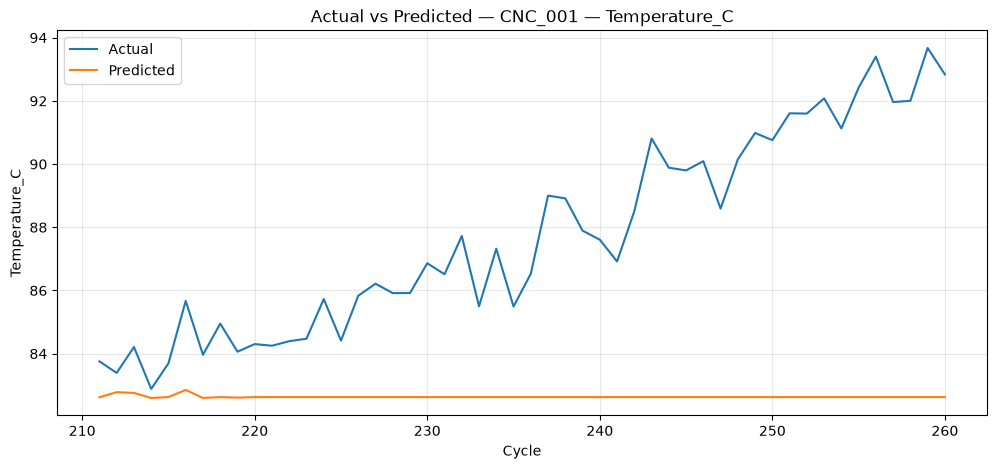

In [10]:
# Plot one representative machine/sensor combination
example_key = next(iter(trained_models.keys()))

machine_id, sensor = example_key
bundle = trained_models[example_key]

test = bundle["test"].copy()
predictions = bundle["model"].predict(test[bundle["feature_cols"]])

plt.figure(figsize=(12, 5))
plt.plot(test["Cycle"], test[sensor].values, label="Actual")
plt.plot(test["Cycle"], predictions, label="Predicted")
plt.title(f"Actual vs Predicted — {machine_id} — {sensor}")
plt.xlabel("Cycle")
plt.ylabel(sensor)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## STEP 11 — Generate test-set predictions for all models

This creates a structured prediction artifact that can be inspected independently and later used by monitoring/integration components.


In [11]:
prediction_records = []

for (machine_id, sensor), bundle in trained_models.items():
    test = bundle["test"].copy()
    model = bundle["model"]
    feature_cols = bundle["feature_cols"]

    preds = model.predict(test[feature_cols])

    for cycle, actual, predicted in zip(
        test["Cycle"],
        test[sensor],
        preds
    ):
        prediction_records.append({
            "Machine_ID": machine_id,
            "Cycle": cycle,
            "Sensor": sensor,
            "Actual_Value": actual,
            "Predicted_Value": predicted,
            "Absolute_Error": abs(actual - predicted),
            "Prediction_Type": "TEST"
        })

test_predictions_df = pd.DataFrame(prediction_records)

display(test_predictions_df.head())
print("Prediction rows:", len(test_predictions_df))


,Machine_ID,Cycle,Sensor,Actual_Value,Predicted_Value,Absolute_Error,Prediction_Type
0,CNC_001,211,Temperature_C,83.755240,82.618365,1.136875,TEST
1,CNC_001,212,Temperature_C,83.391194,82.781581,0.609613,TEST
2,CNC_001,213,Temperature_C,84.210066,82.757086,1.452981,TEST
3,CNC_001,214,Temperature_C,82.884632,82.596613,0.288019,TEST
4,CNC_001,215,Temperature_C,83.693984,82.626411,1.067573,TEST


Prediction rows: 1116


## STEP 12 — Recursive forecasting of future sensor values

Now we perform the most important time-series operation:

> Predict sensor values for future cycles that do not yet exist in the observed data.

We use recursive forecasting:

```text
known history
    ↓
predict t+1
    ↓
use prediction as history
    ↓
predict t+2
    ↓
...
```

The default horizon is 10 future cycles.


In [12]:
FORECAST_HORIZON = 10

def recursive_forecast(model, history_values, horizon, lags=LAGS):
    history = list(history_values)
    forecasts = []

    for _ in range(horizon):
        features = np.array([
            history[-lag]
            for lag in lags
        ], dtype=float).reshape(1, -1)

        prediction = float(model.predict(features)[0])
        forecasts.append(prediction)
        history.append(prediction)

    return forecasts

future_records = []

for (machine_id, sensor), bundle in trained_models.items():
    machine_history = (
        df[df["Machine_ID"] == machine_id]
        .sort_values("Cycle")[sensor]
        .dropna()
        .tolist()
    )

    if len(machine_history) < max(LAGS):
        continue

    model = bundle["model"]

    forecasts = recursive_forecast(
        model=model,
        history_values=machine_history,
        horizon=FORECAST_HORIZON
    )

    last_cycle = int(
        df[df["Machine_ID"] == machine_id]["Cycle"].max()
    )

    for step, value in enumerate(forecasts, start=1):
        future_records.append({
            "Machine_ID": machine_id,
            "Cycle": last_cycle + step,
            "Sensor": sensor,
            "Actual_Value": np.nan,
            "Predicted_Value": value,
            "Absolute_Error": np.nan,
            "Prediction_Type": "FUTURE_FORECAST",
            "Forecast_Horizon": step
        })

future_forecasts_df = pd.DataFrame(future_records)

display(future_forecasts_df.head(20))
print("Future forecast rows:", len(future_forecasts_df))


,Machine_ID,Cycle,Sensor,Actual_Value,Predicted_Value,Absolute_Error,Prediction_Type,Forecast_Horizon
0,CNC_001,261,Temperature_C,NaN,82.625170,NaN,FUTURE_FORECAST,1
1,CNC_001,262,Temperature_C,NaN,82.657579,NaN,FUTURE_FORECAST,2
2,CNC_001,263,Temperature_C,NaN,82.691742,NaN,FUTURE_FORECAST,3
3,CNC_001,264,Temperature_C,NaN,82.643994,NaN,FUTURE_FORECAST,4
4,CNC_001,265,Temperature_C,NaN,82.637701,NaN,FUTURE_FORECAST,5
5,CNC_001,266,Temperature_C,NaN,82.653886,NaN,FUTURE_FORECAST,6
6,CNC_001,267,Temperature_C,NaN,82.632086,NaN,FUTURE_FORECAST,7
7,CNC_001,268,Temperature_C,NaN,82.613808,NaN,FUTURE_FORECAST,8
8,CNC_001,269,Temperature_C,NaN,82.634315,NaN,FUTURE_FORECAST,9
9,CNC_001,270,Temperature_C,NaN,82.634315,NaN,FUTURE_FORECAST,10


Future forecast rows: 210


## STEP 13 — Visualize future forecasts

The final section of each machine's observed history is followed by the predicted future trajectory.


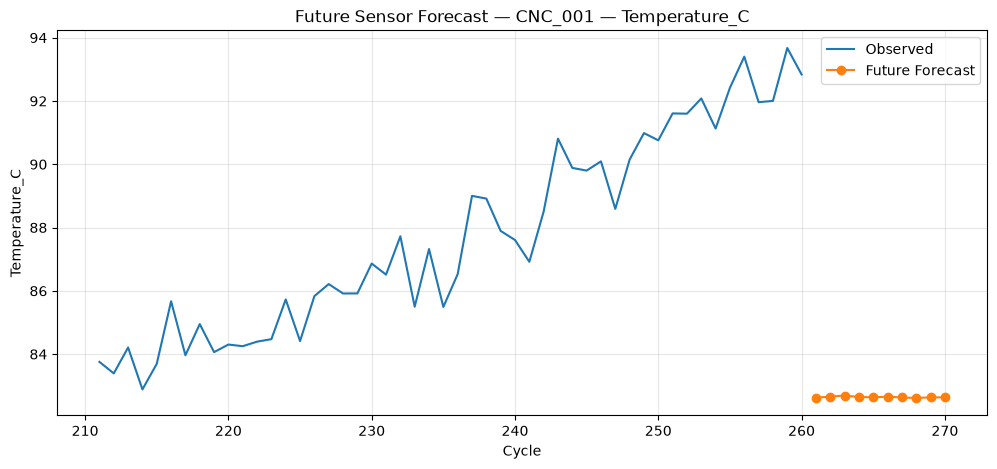

In [13]:
machine_id, sensor = next(iter(trained_models.keys()))

history = (
    df[df["Machine_ID"] == machine_id]
    .sort_values("Cycle")
)

future = future_forecasts_df[
    (future_forecasts_df["Machine_ID"] == machine_id) &
    (future_forecasts_df["Sensor"] == sensor)
].sort_values("Cycle")

plt.figure(figsize=(12, 5))

plt.plot(
    history["Cycle"].tail(50),
    history[sensor].tail(50),
    label="Observed"
)

plt.plot(
    future["Cycle"],
    future["Predicted_Value"],
    marker="o",
    label="Future Forecast"
)

plt.title(f"Future Sensor Forecast — {machine_id} — {sensor}")
plt.xlabel("Cycle")
plt.ylabel(sensor)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## STEP 14 — Combine and save forecasting outputs

Two artifacts are saved:

1. `time_series_forecasts.csv` — actual test predictions + future forecasts
2. `time_series_forecast_metrics.csv` — MAE/RMSE for each machine/sensor model

These files become inputs for later monitoring and integration work.


In [14]:
all_forecasts = pd.concat(
    [test_predictions_df, future_forecasts_df],
    ignore_index=True
)

# Ensure the output directory exists.
os.makedirs(os.path.dirname(FORECAST_OUTPUT_PATH), exist_ok=True)

all_forecasts.to_csv(FORECAST_OUTPUT_PATH, index=False)
metrics_df.to_csv(METRICS_OUTPUT_PATH, index=False)

print("Saved:")
print("-", FORECAST_OUTPUT_PATH)
print("-", METRICS_OUTPUT_PATH)

print("\nForecast output shape:", all_forecasts.shape)
print("Metrics output shape:", metrics_df.shape)


Saved:
- ../data/processed/time_series_forecasts.csv
- ../data/processed/time_series_forecast_metrics.csv

Forecast output shape: (1326, 8)
Metrics output shape: (21, 6)


## STEP 15 — Forecast deviation as a future Smart Twin signal

One of the most useful consequences of this notebook is that forecasting error can become a monitoring feature.

For an observed cycle:

```text
Forecast error = |Actual sensor value - Predicted sensor value|
```

A consistently increasing forecast error can indicate that machine behavior is changing away from the learned normal pattern.

Conceptually:

```text
Time-Series Forecast
        ↓
Expected Sensor Value
        ↓
Compare with Actual
        ↓
Forecast Deviation
        ↓
Smart Twin Evidence
        ↓
Failure / Degradation Assessment
```

This does **not** replace the existing failure model. It adds another independent signal.

The next integration stage can combine:

- failure probability
- RUL
- anomaly score
- health index
- forecast deviation

before the Maintenance/Alert Agents are invoked.


In [15]:
# Simple summary of forecast error on the held-out test data.

forecast_error_summary = (
    test_predictions_df
    .groupby(["Machine_ID", "Sensor"], as_index=False)
    .agg(
        Mean_Absolute_Error=("Absolute_Error", "mean"),
        Max_Absolute_Error=("Absolute_Error", "max")
    )
)

display(forecast_error_summary)


,Machine_ID,Sensor,Mean_Absolute_Error,Max_Absolute_Error
0,CNC_001,Pressure_bar,0.034376,0.083900
1,CNC_001,Temperature_C,5.097954,11.049412
2,CNC_001,Vibration_mm_s,0.347378,0.740204
3,COMP_003,Pressure_bar,0.032507,0.119760
4,COMP_003,Temperature_C,4.774992,10.056621
5,COMP_003,Vibration_mm_s,0.389138,0.828703
6,MOTOR_004,Pressure_bar,0.057638,0.145367
7,MOTOR_004,Temperature_C,3.667262,6.811092
8,MOTOR_004,Vibration_mm_s,0.105852,0.222715
9,PRESS_006,Pressure_bar,0.117527,0.247674


## STEP 16 — Final validation

Run these checks before considering the notebook complete.

Expected:

- input data loads successfully
- all selected sensors exist
- models are trained
- MAE/RMSE are numeric
- test predictions are generated
- future forecasts are generated
- output CSV files exist

This notebook intentionally does not call the LLM. The LLM remains downstream of the orchestrated maintenance workflow.


In [16]:
print("=" * 60)
print("TIME-SERIES FORECASTING VALIDATION")
print("=" * 60)

print("Input rows:", len(df))
print("Machines:", df["Machine_ID"].nunique())
print("Sensors:", SENSORS)
print("Models trained:", len(trained_models))
print("Test prediction rows:", len(test_predictions_df))
print("Future forecast rows:", len(future_forecasts_df))
print("Average MAE:", round(metrics_df["MAE"].mean(), 4))
print("Average RMSE:", round(metrics_df["RMSE"].mean(), 4))
print("Forecast output exists:", os.path.exists(FORECAST_OUTPUT_PATH))
print("Metrics output exists:", os.path.exists(METRICS_OUTPUT_PATH))

assert len(trained_models) > 0
assert len(test_predictions_df) > 0
assert len(future_forecasts_df) > 0
assert os.path.exists(FORECAST_OUTPUT_PATH)
assert os.path.exists(METRICS_OUTPUT_PATH)

print("\nSTATUS: TIME-SERIES FORECASTING PIPELINE COMPLETED SUCCESSFULLY")


TIME-SERIES FORECASTING VALIDATION
Input rows: 1930
Machines: 7
Sensors: ['Temperature_C', 'Vibration_mm_s', 'Pressure_bar']
Models trained: 21
Test prediction rows: 1116
Future forecast rows: 210
Average MAE: 1.4405
Average RMSE: 1.6646
Forecast output exists: True
Metrics output exists: True

STATUS: TIME-SERIES FORECASTING PIPELINE COMPLETED SUCCESSFULLY


# End of Notebook

### What this component adds to the project

The project now has both:

**1. Predictive maintenance**

```text
sensor telemetry → failure probability + RUL
```

and

**2. Sensor forecasting**

```text
historical sensor telemetry → future sensor values
```

The two capabilities can later be combined to strengthen anomaly detection and model monitoring.

### Next project layer

After validating this notebook, the next requirement to implement is:

> **Monitoring / Evaluation — Model degradation monitoring**

That layer will use the prediction/forecasting outputs and evaluate model quality, drift, and degradation over time.
